In [1]:
# 0. 라이브러리
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
from joblib import Parallel, delayed
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold
from sklearn.metrics import (f1_score, accuracy_score, precision_score, recall_score, roc_auc_score,
                             classification_report, confusion_matrix)

RS = 42
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

In [2]:
# 1. 데이터 불러오기 + 팀 공통 Train/Test 분할 (index 파일 기준, 80:20 층화)
df = pd.read_csv(ROOT / "data/processed/Faults_processed.csv")      # 원본 26개 피처 + target (A400 제외된 상태)
train_idx = pd.read_csv(ROOT / "data/split/train_idx.csv")["index"]
test_idx = pd.read_csv(ROOT / "data/split/test_idx.csv")["index"]

X, y = df.drop(columns="target"), df["target"]
X_train, X_test = X.loc[train_idx], X.loc[test_idx]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]
print("Train", X_train.shape, "| Test", X_test.shape)

Train (1552, 26) | Test (389, 26)


In [3]:
# 2. 파생변수 10개 생성
PLATE_KEYS = ["Length_of_Conveyer", "Steel_Plate_Thickness", "TypeOfSteel_A300"]   # 강판 조건
DISCRETE = ["TypeOfSteel_A300", "Outside_Global_Index"]                             # 이산형 변수 (마지막 열로 배치)

def plate_key(X):
    return X[PLATE_KEYS].astype(str).agg("_".join, axis=1)

def add_features(X, plate_counts):
    out = X.copy()
    width = (X["X_Maximum"] - X["X_Minimum"]).clip(lower=0)
    mx, mn = X["Maximum_of_Luminosity"], X["Minimum_of_Luminosity"]
    # 형상
    out["compactness"] = (X["X_Perimeter"] + X["Y_Perimeter"]) / np.sqrt(X["Pixels_Areas"])   # 둘레 대비 면적
    out["perimeter_ratio_log"] = np.log((X["X_Perimeter"] + 1) / (X["Y_Perimeter"] + 1))      # 가로/세로 둘레 비
    out["x_straightness"] = X["X_Perimeter"] / (width + 1)                                     # 가로 윤곽의 굴곡
    # 밝기
    out["lum_range"] = mx - mn                                                                 # 밝기 범위
    out["lum_contrast"] = (mx - mn) / (mx + mn).replace(0, 1)                                  # 상대 대비
    out["lum_mean_position"] = (X["Sum_of_Luminosity"] / X["Pixels_Areas"] - mn) / (mx - mn + 1)  # 평균 밝기의 위치
    # 위치
    xc = (X["X_Minimum"] + X["X_Maximum"]) / 2 / X["Length_of_Conveyer"]
    out["x_center_rel"] = xc                                                                   # 컨베이어 폭 대비 중심 위치
    out["x_center_dist"] = (xc - 0.5).abs()                                                    # 중앙에서 떨어진 정도
    # 강판 맥락
    out["plate_defect_count"] = plate_key(X).map(plate_counts).fillna(0).astype(float)        # 같은 강판 조건의 결함 수 (처음 보는 조건 = 0)
    out["thickness_per_conveyer"] = X["Steel_Plate_Thickness"] / X["Length_of_Conveyer"]
    # 연속형 → 이산형 순서로 열 정렬 (학습·평가 열 순서 고정)
    return out[[c for c in out.columns if c not in DISCRETE] + DISCRETE]

In [4]:
# 3. 최종 모델: ExtraTrees + Random Forest + GBM Soft Voting (36개 피처에서 튜닝한 하이퍼파라미터)
def fit_soft_voting(X_tr, y_tr, n_jobs=-1):
    plate_counts = plate_key(X_tr).value_counts().to_dict()      # 강판 조건별 결함 수는 학습 데이터로만 계산 (누수 방지)
    Xf = add_features(X_tr, plate_counts)
    et = ExtraTreesClassifier(n_estimators=438, max_depth=15, max_features=0.7, min_samples_leaf=1,
                              class_weight="balanced", random_state=RS, n_jobs=n_jobs)     # 불균형: 클래스 가중치
    rf = RandomForestClassifier(n_estimators=483, max_depth=None, max_features=0.3, min_samples_leaf=1,
                                random_state=RS, n_jobs=n_jobs)                             # 불균형 처리 없음
    gbm = GradientBoostingClassifier(n_estimators=240, learning_rate=0.08793919399591556, max_depth=4,
                                     subsample=0.9079017872741743, max_features=0.5, min_samples_leaf=5,
                                     random_state=RS)
    # GBM은 class_weight 인자가 없으므로 균형 가중치를 sample_weight로 전달: w_c = 최다 클래스 건수 / 클래스 c 건수
    counts = y_tr.value_counts()
    et.fit(Xf, y_tr); rf.fit(Xf, y_tr); gbm.fit(Xf, y_tr, sample_weight=y_tr.map(counts.max() / counts).to_numpy())
    return [et, rf, gbm], plate_counts

def predict_soft_voting(models, plate_counts, X_new):
    Xf = add_features(X_new, plate_counts)
    proba = np.mean([m.predict_proba(Xf) for m in models], axis=0)   # 세 모델의 클래스별 확률 평균
    pred = models[0].classes_[proba.argmax(axis=1)]                   # 확률이 가장 높은 클래스
    return pred, proba

def metrics(y_true, pred, proba, classes):
    return {"Macro F1": f1_score(y_true, pred, average="macro"),
            "Accuracy": accuracy_score(y_true, pred),
            "Macro Precision": precision_score(y_true, pred, average="macro"),
            "Macro Recall": recall_score(y_true, pred, average="macro"),
            "Weighted F1": f1_score(y_true, pred, average="weighted"),
            "Macro ROC-AUC": roc_auc_score(y_true, proba, multi_class="ovr", average="macro", labels=classes)}

In [5]:
# 4-1. 팀 공통 기준: Train 내부 StratifiedKFold 5-fold (shuffle=True, random_state=42)
def eval_fold(tr, va):
    # fold마다 학습 fold로만 파생변수(강판 조건별 결함 수)·모델 학습 → 검증 fold 평가
    models, pc = fit_soft_voting(X_train.iloc[tr], y_train.iloc[tr], n_jobs=1)
    pred, proba = predict_soft_voting(models, pc, X_train.iloc[va])
    return metrics(y_train.iloc[va], pred, proba, models[0].classes_)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
cv5_scores = pd.DataFrame(Parallel(n_jobs=-1)(delayed(eval_fold)(tr, va) for tr, va in cv.split(X_train, y_train)))
cv5_scores.index = [f"fold {i + 1}" for i in range(len(cv5_scores))]
print(f"5-fold CV Macro F1 : {cv5_scores['Macro F1'].mean():.4f} ± {cv5_scores['Macro F1'].std(ddof=0):.4f}")
cv5_summary = pd.DataFrame({"평균": cv5_scores.mean(), "표준편차": cv5_scores.std(ddof=0)}).round(4)   # 지표별 5 fold 평균 ± 표준편차
cv5_summary

5-fold CV Macro F1 : 0.8441 ± 0.0188


,평균,표준편차
Macro F1,0.8441,0.0188
Accuracy,0.8183,0.0160
Macro Precision,0.8638,0.0258
Macro Recall,0.8310,0.0198
Weighted F1,0.8181,0.0158
Macro ROC-AUC,0.9718,0.0024


In [6]:
# 4-2. 추가 검증: 반복 층화 CV (5-fold × 3회 = 15 fold) — 분할 운의 영향을 줄인 평균
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RS)

cv_scores = pd.DataFrame(Parallel(n_jobs=-1)(delayed(eval_fold)(tr, va) for tr, va in rcv.split(X_train, y_train)))   # 몇 분 소요
cv_scores.index = [f"fold {i + 1}" for i in range(len(cv_scores))]
print(f"반복 CV(5×3) Macro F1 : {cv_scores['Macro F1'].mean():.4f} ± {cv_scores['Macro F1'].std(ddof=0):.4f}"
      f"   (0.83 이상 fold {(cv_scores['Macro F1'] >= 0.83).sum()}/15)")
cv_summary = pd.DataFrame({"평균": cv_scores.mean(), "표준편차": cv_scores.std(ddof=0)}).round(4)   # 지표별 15 fold 평균 ± 표준편차
cv_summary

반복 CV(5×3) Macro F1 : 0.8389 ± 0.0231   (0.83 이상 fold 10/15)


,평균,표준편차
Macro F1,0.8389,0.0231
Accuracy,0.8127,0.0208
Macro Precision,0.8562,0.0266
Macro Recall,0.8272,0.0262
Weighted F1,0.8127,0.0207
Macro ROC-AUC,0.9706,0.0053


In [7]:
# 4-3. 과적합 점검: 같은 5-fold에서 학습 fold 점수 vs 검증 fold 점수 (모델별)
def overfit_fold(tr, va):
    X_tr, y_tr, X_va, y_va = X_train.iloc[tr], y_train.iloc[tr], X_train.iloc[va], y_train.iloc[va]
    models, pc = fit_soft_voting(X_tr, y_tr, n_jobs=1)
    F_tr, F_va = add_features(X_tr, pc), add_features(X_va, pc)
    row = {}
    for name, m in zip(["ExtraTrees", "Random Forest", "GBM"], models):              # 구성 모델 각각
        row[(name, "Train")] = f1_score(y_tr, m.predict(F_tr), average="macro")
        row[(name, "Validation")] = f1_score(y_va, m.predict(F_va), average="macro")
    row[("Soft Voting", "Train")] = f1_score(y_tr, predict_soft_voting(models, pc, X_tr)[0], average="macro")
    row[("Soft Voting", "Validation")] = f1_score(y_va, predict_soft_voting(models, pc, X_va)[0], average="macro")
    return row

of = pd.DataFrame(Parallel(n_jobs=-1)(delayed(overfit_fold)(tr, va) for tr, va in cv.split(X_train, y_train)))
of.columns = pd.MultiIndex.from_tuples(of.columns)                                # (모델, Train/Validation)
overfit = of.mean().unstack()[["Train", "Validation"]]
overfit["Gap (Train − Validation)"] = overfit["Train"] - overfit["Validation"]
overfit["Validation 표준편차"] = of.xs("Validation", axis=1, level=1).std(ddof=0)
overfit.round(4)

,Train,Validation,Gap (Train − Validation),Validation 표준편차
ExtraTrees,1.0,0.8180,0.1820,0.0185
GBM,1.0,0.8401,0.1599,0.0159
Random Forest,1.0,0.8125,0.1875,0.0218
Soft Voting,1.0,0.8441,0.1559,0.0188


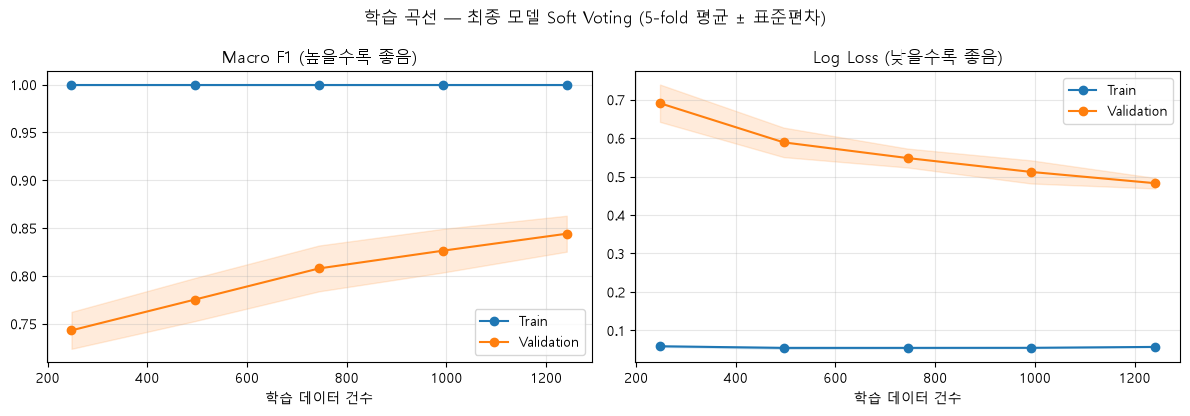

,학습 건수,Train F1,Validation F1,Train Loss,Validation Loss
학습 비율,,,,,
0.2,248.0,1.0,0.7430,0.0587,0.6907
0.4,496.0,1.0,0.7753,0.0545,0.5890
0.6,744.6,1.0,0.8078,0.0546,0.5482
0.8,992.6,1.0,0.8263,0.0547,0.5120
1.0,1241.6,1.0,0.8441,0.0571,0.4827


In [8]:
# 4-4. 학습 곡선: 학습 데이터 양을 늘릴 때 Train/Validation 성능(Macro F1)과 손실(Log Loss) 변화
#      (같은 5-fold, 각 학습 fold에서 일부만 층화 추출해 학습 → 같은 검증 fold로 평가)
import matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss

for font in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:   # 한글 폰트 (Windows: 맑은 고딕)
    if any(font == f.name for f in mpl.font_manager.fontManager.ttflist):
        mpl.rcParams["font.family"] = font; break
mpl.rcParams["axes.unicode_minus"] = False

def lc_fold(tr, va, frac):
    X_tr, y_tr = X_train.iloc[tr], y_train.iloc[tr]
    if frac < 1:   # 학습 fold에서 frac 비율만 클래스 비율을 유지하며 추출
        X_tr, _, y_tr, _ = train_test_split(X_tr, y_tr, train_size=frac, stratify=y_tr, random_state=RS)
    models, pc = fit_soft_voting(X_tr, y_tr, n_jobs=1)
    classes = models[0].classes_
    pred_tr, proba_tr = predict_soft_voting(models, pc, X_tr)
    pred_va, proba_va = predict_soft_voting(models, pc, X_train.iloc[va])
    y_va = y_train.iloc[va]
    return {"학습 비율": frac, "학습 건수": len(y_tr),
            "Train F1": f1_score(y_tr, pred_tr, average="macro"), "Validation F1": f1_score(y_va, pred_va, average="macro"),
            "Train Loss": log_loss(y_tr, proba_tr, labels=classes), "Validation Loss": log_loss(y_va, proba_va, labels=classes)}

FRACS = [0.2, 0.4, 0.6, 0.8, 1.0]
lc = pd.DataFrame(Parallel(n_jobs=-1)(delayed(lc_fold)(tr, va, f) for f in FRACS for tr, va in cv.split(X_train, y_train)))   # 몇 분 소요
lc_mean, lc_std = lc.groupby("학습 비율").mean(), lc.groupby("학습 비율").std(ddof=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, key, title in [(axes[0], "F1", "Macro F1 (높을수록 좋음)"), (axes[1], "Loss", "Log Loss (낮을수록 좋음)")]:
    for part, color in [("Train", "tab:blue"), ("Validation", "tab:orange")]:
        m, s = lc_mean[f"{part} {key}"], lc_std[f"{part} {key}"]
        ax.plot(lc_mean["학습 건수"], m, "o-", color=color, label=part)
        ax.fill_between(lc_mean["학습 건수"], m - s, m + s, color=color, alpha=0.15)   # 5-fold 표준편차
    ax.set_xlabel("학습 데이터 건수"); ax.set_title(title); ax.grid(alpha=0.3); ax.legend()
fig.suptitle("학습 곡선 — 최종 모델 Soft Voting (5-fold 평균 ± 표준편차)")
plt.tight_layout(); plt.show()
lc_mean.round(4)

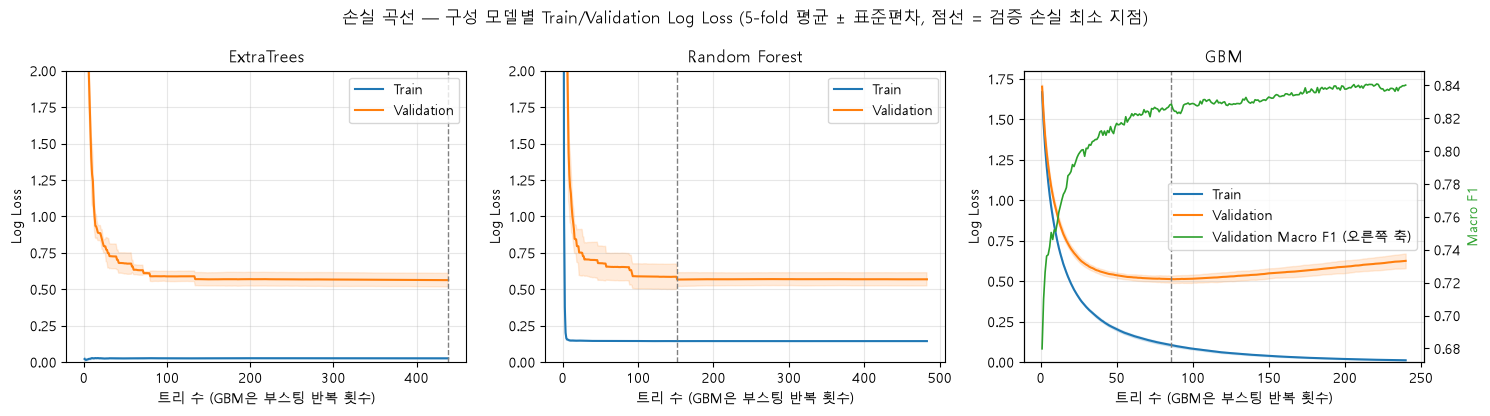

,트리 수(최종),Train Loss 최종,Validation Loss 최소,최소 지점(트리 수),Validation Loss 최종,검증 F1 @손실 최소,검증 F1 최대,F1 최대 지점,검증 F1 최종
ExtraTrees,438.0,0.0258,0.5623,438.0,0.5623,NaN,NaN,NaN,NaN
Random Forest,483.0,0.1437,0.5658,152.0,0.5679,NaN,NaN,NaN,NaN
GBM,240.0,0.0110,0.5118,86.0,0.6250,0.8284,0.8408,221.0,0.8401


In [9]:
# 4-5. 손실 곡선: 트리 수(학습 반복)가 늘어날 때 Train/Validation Log Loss 변화 — 구성 모델별 (같은 5-fold)
#      검증 손실이 어느 시점부터 다시 올라가면 과적합 신호
def loss_curves(tr, va):
    X_tr, y_tr, X_va, y_va = X_train.iloc[tr], y_train.iloc[tr], X_train.iloc[va], y_train.iloc[va]
    models, pc = fit_soft_voting(X_tr, y_tr, n_jobs=1)
    F_tr, F_va = add_features(X_tr, pc), add_features(X_va, pc)
    out = {}
    for name, m in zip(["ExtraTrees", "Random Forest"], models[:2]):          # 배깅: 트리 1개 ~ N개까지 누적 평균 확률
        for part, F, y in [("Train", F_tr, y_tr), ("Validation", F_va, y_va)]:
            P = np.cumsum([t.predict_proba(F.values) for t in m.estimators_], axis=0)   # 개별 트리는 배열 입력
            P /= np.arange(1, len(m.estimators_) + 1)[:, None, None]
            out[(name, part)] = [log_loss(y, p, labels=m.classes_) for p in P]
    gbm = models[2]                                                            # 부스팅: 반복(트리) 단계별 확률
    for part, F, y in [("Train", F_tr, y_tr), ("Validation", F_va, y_va)]:
        out[("GBM", part)] = [log_loss(y, p, labels=gbm.classes_) for p in gbm.staged_predict_proba(F)]
    out[("GBM", "Validation F1")] = [f1_score(y_va, p, average="macro") for p in gbm.staged_predict(F_va)]   # 반복별 검증 Macro F1
    return out

curves = Parallel(n_jobs=-1)(delayed(loss_curves)(tr, va) for tr, va in cv.split(X_train, y_train))   # 몇 분 소요

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
loss_summary = {}
for ax, name in zip(axes, ["ExtraTrees", "Random Forest", "GBM"]):
    tr_arr = np.array([c[(name, "Train")] for c in curves])                   # (fold, 트리 수)
    va_arr = np.array([c[(name, "Validation")] for c in curves])
    x = np.arange(1, tr_arr.shape[1] + 1)
    for arr, part, color in [(tr_arr, "Train", "tab:blue"), (va_arr, "Validation", "tab:orange")]:
        ax.plot(x, arr.mean(0), color=color, label=part)
        ax.fill_between(x, arr.mean(0) - arr.std(0), arr.mean(0) + arr.std(0), color=color, alpha=0.15)
    best = int(va_arr.mean(0).argmin()) + 1                                    # 검증 손실이 가장 낮은 트리 수
    ax.axvline(best, color="gray", ls="--", lw=1)
    ax.set_xlabel("트리 수 (GBM은 부스팅 반복 횟수)"); ax.set_ylabel("Log Loss"); ax.set_title(name)
    ax.set_ylim(0, 2 if name != "GBM" else None); ax.grid(alpha=0.3)   # 배깅은 트리 1~2개일 때 손실이 매우 커서 0~2 구간만 표시
    if name == "GBM":   # GBM은 반복별 검증 Macro F1도 함께 (오른쪽 축)
        f1_arr = np.array([c[("GBM", "Validation F1")] for c in curves])
        ax2 = ax.twinx(); ax2.plot(x, f1_arr.mean(0), color="tab:green", lw=1.2, label="Validation Macro F1 (오른쪽 축)")
        ax2.set_ylabel("Macro F1", color="tab:green")
        h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
        ax.legend(h1 + h2, l1 + l2, loc="center right")
    else:
        ax.legend(loc="upper right")
    loss_summary[name] = {"트리 수(최종)": len(x), "Train Loss 최종": tr_arr.mean(0)[-1],
                          "Validation Loss 최소": va_arr.mean(0).min(), "최소 지점(트리 수)": best,
                          "Validation Loss 최종": va_arr.mean(0)[-1]}
f1_mean = np.array([c[("GBM", "Validation F1")] for c in curves]).mean(0)
loss_summary["GBM"].update({"검증 F1 @손실 최소": f1_mean[loss_summary["GBM"]["최소 지점(트리 수)"] - 1],
                            "검증 F1 최대": f1_mean.max(), "F1 최대 지점": int(f1_mean.argmax()) + 1, "검증 F1 최종": f1_mean[-1]})
fig.suptitle("손실 곡선 — 구성 모델별 Train/Validation Log Loss (5-fold 평균 ± 표준편차, 점선 = 검증 손실 최소 지점)")
plt.tight_layout(); plt.show()
pd.DataFrame(loss_summary).T.round(4)

In [10]:
# 5. Train 전체로 학습 → Test 예측
models, plate_counts = fit_soft_voting(X_train, y_train)
pred, proba = predict_soft_voting(models, plate_counts, X_test)

In [11]:
# 6. Test 성능
order = ["Other_Faults", "Bumps", "K_Scratch", "Z_Scratch", "Pastry", "Stains", "Dirtiness"]
test_scores = pd.Series(metrics(y_test, pred, proba, models[0].classes_)).round(4)
print("Test 성능"); print(test_scores.to_string(), "\n")
print(f"CV(5-fold) Macro F1 {cv5_scores['Macro F1'].mean():.4f} vs Test {test_scores['Macro F1']:.4f}  → 차이 {cv5_scores['Macro F1'].mean() - test_scores['Macro F1']:+.4f}\n")   # 과적합 점검: 처음 보는 데이터에서도 CV 수준 유지되는지
print(classification_report(y_test, pred, labels=order, digits=3))
pd.DataFrame(confusion_matrix(y_test, pred, labels=order), index=order, columns=order)   # 행 = 실제, 열 = 예측

Test 성능
Macro F1           0.8324
Accuracy           0.8098
Macro Precision    0.8486
Macro Recall       0.8182
Weighted F1        0.8123
Macro ROC-AUC      0.9686 

CV(5-fold) Macro F1 0.8441 vs Test 0.8324  → 차이 +0.0117

              precision    recall  f1-score   support

Other_Faults      0.745     0.800     0.771       135
       Bumps      0.756     0.728     0.742        81
   K_Scratch      0.986     0.923     0.954        78
   Z_Scratch      1.000     0.947     0.973        38
      Pastry      0.529     0.562     0.545        32
      Stains      0.923     0.857     0.889        14
   Dirtiness      1.000     0.909     0.952        11

    accuracy                          0.810       389
   macro avg      0.849     0.818     0.832       389
weighted avg      0.816     0.810     0.812       389



,Other_Faults,Bumps,K_Scratch,Z_Scratch,Pastry,Stains,Dirtiness
Other_Faults,108,14,1,0,11,1,0
Bumps,18,59,0,0,4,0,0
K_Scratch,5,0,72,0,1,0,0
Z_Scratch,2,0,0,36,0,0,0
Pastry,10,4,0,0,18,0,0
Stains,1,1,0,0,0,12,0
Dirtiness,1,0,0,0,0,0,10


In [12]:
# 7. 모델 저장 — 세 모델 + 강판 조건별 결함 수(Train 기준)를 함께 저장 (예측 시 파생변수 계산에 필요)
MODEL_PATH = ROOT / "models" / "Taegyeom_final_model_trained.pkl"
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
bundle = {"models": models,                      # [ExtraTrees, RandomForest, GBM]
          "plate_counts": plate_counts,          # plate_defect_count 계산용
          "feature_columns": list(add_features(X_train.head(1), plate_counts).columns),   # 학습 시 열 순서 (36개)
          "test_macro_f1": round(f1_score(y_test, pred, average="macro"), 4)}
joblib.dump(bundle, MODEL_PATH, compress=3)      # 압축 저장 (약 16MB)
print("저장:", MODEL_PATH)

저장: c:\Users\tae37\Desktop\workspace1\steel-plate-fault-classification\models\Taegyeom_final_model_trained.pkl
